# Training of airgun classifier

### Training data

we have a set of 150 files annotated of a total of 474. The files are annotated in raven with a single class. 

### Models to try

Altough the annotations are boxes i though of using start and finish to train a perch like model  that works in chunks and also a model based on the waveform.; The waveform model i never trained before. 

- YOLO detection model (ultralytics, opensoudnscape, hugginface)
-  ResnEt deteciton model (opensoudnscape, hugginface)
- Perch or Birdnet style model (opensoundscape)
- Wav2Vec2-BERT based on waveforms  (huggin face)

# Pre processing
The raven labels might need some work because raven lite does not create all the columns i need to create. 

Since most airguns are very lo frequency, i will like to do a band  pass on the data and annotations before hand. 


### Proposed workflow

Load the data -> band filter pass  -> divide the annotations between, start and finish or boxes -> split into train and test (100,150) -> train all models -> run on the rest of the data ->  active learning?

In [ ]:
### Object detection models based on spectograms

In [4]:
from opensoundscape import Audio, Spectrogram
from opensoundscape.annotations import BoxedAnnotations

import numpy as np
import pandas as pd
from glob import glob
from pathlib import Path

import matplotlib.pyplot as plt

# load the annotation file from Raven
annotation_file = r"C:\Users\247404\Documents\2024\HABITWAL FINAL REPORT\Airgun_detector\annotations_airguns150.txt"
audio_file = r"J:\HABITATWal\AMAR\HABITATWal.RDS\Sound Catalog AMARs\Airgun\all_together.wav"


AttributeError: partially initialized module 'torch' has no attribute 'fx' (most likely due to a circular import)

Here i load an example audio, the bandpass cuts the frequencies outside my range

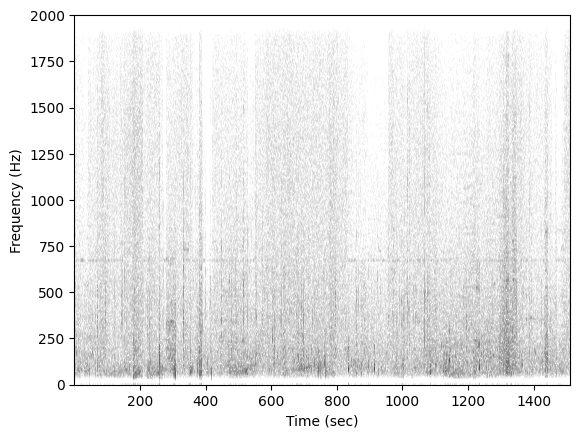

In [ ]:
audio = Audio.from_file(audio_file).bandpass(low_f=50, high_f=2000, order=4).resample(4000)   
Spectrogram.from_audio(audio, fft_size=1024*4).plot()

Load raven file, however opensoundscape only takes singel annotation files per audiofile which is super strange to me. I will need to write a small snippet to divide my annotation file into subfiles

In [2]:
annot_list = [annotation_file]
audio_list = [audio_file]

# Create an object from Raven file
annotations = BoxedAnnotations.from_raven_files(
    raven_files=annot_list,
    audio_files=audio_list,
    annotation_column=None,  # Put None if you don't have an annotation column
)

# Inspect the object's .df attribute
# which contains the table of annotations
annotations.df.head()
annotations.df["annotation"] = "airgun"

NameError: name 'annotation_file' is not defined

In [13]:

# Parameters to use for label creation
clip_duration = 10
clip_overlap = 0
min_label_overlap = 0.25

# Create dataframe of one-hot labels
clip_labels = annotations.clip_labels(
    clip_duration = clip_duration,
    clip_overlap = clip_overlap,
    min_label_overlap = min_label_overlap,
)

clips with airguns labels:



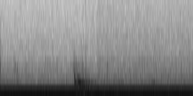
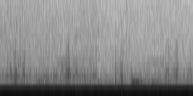
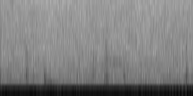
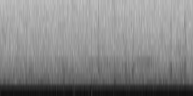

In [14]:
from opensoundscape.visualization import inspect

print(f"clips with airguns labels:")
widget = inspect(
    clip_labels, N=4, bandpass_range=(0, 2000)
)


Create test, train and validation script, 

In [17]:
labels = clip_labels.sort_index(level="start_time")
n = len(labels)
train_df = labels.iloc[: int(0.5 * n)]
val_df   = labels.iloc[int(0.5 * n) : int(0.85 * n)]
test_df  = labels.iloc[int(0.85 * n) :]

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(name, len(d), "clips,",d["airgun"].sum(), "with airgun")

train 76 clips, 67 with airgun
val 53 clips, 47 with airgun
test 23 clips, 22 with airgun


In [11]:
from opensoundscape.ml.cnn_architectures import list_architectures; list_architectures()

['resnet18',
 'resnet34',
 'resnet50',
 'resnet101',
 'resnet152',
 'alexnet',
 'vgg11_bn',
 'squeezenet1_0',
 'densenet121',
 'efficientnet_b0',
 'efficientnet_b1',
 'efficientnet_b4']

In [19]:
# Create a CNN object designed to recognize 3-second samples
from opensoundscape import CNN

# Use resnet34 architecture
architecture = "resnet152"

# Can use this code to get your classes, if needed
class_list = list(train_df.columns)
class_list
model = CNN(
    architecture=architecture,
    classes=class_list,
    sample_duration=clip_duration,  # 10s, selected above
    sample_rate=6000,
)

Downloading: "https://download.pytorch.org/models/resnet152-f82ba261.pth" to C:\Users\247404/.cache\torch\hub\checkpoints\resnet152-f82ba261.pth


100%|██████████| 230M/230M [00:20<00:00, 11.5MB/s] 


In [21]:
print(f"model.device is: {model.device}")


model.device is: cpu


In [22]:
import torch; print(torch.__version__, torch.cuda.is_available())

2.14.1+cpu False
